# GameForge AI — LPC Sprite Dataset Audit & Action Generation Training

**Goal:** use both Hugging Face LPC datasets to prepare sprite data, train a model, and export inference utilities for sprite-sheet / action-frame generation.

> **Important limitation:** the two datasets previously inspected exposed only an `image` column. That alone does not prove which images are matched character references, nor which frames represent `walk`, `run`, `idle`, etc. This notebook audits the data first and refuses to invent labels or matching pairs. If the dataset really has only unlabelled images and no consistent sheet layout, it cannot reliably learn controllable walk/run actions without additional labels or a verified spritesheet convention.

This notebook is designed for a Kaggle GPU (e.g. Tesla T4). It does **not** use the separate synthetic-affine baseline notebook, and it does not silently replace the code in your ZIP. It is a data/training workflow for the two Hugging Face datasets.

## 1. Install dependencies
Run once per fresh Kaggle session. Internet must be enabled for Hugging Face downloads.

In [1]:
!pip -q install -U datasets huggingface_hub pillow matplotlib tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.3.0 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.3.0 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.3.0 which is incompatible.
g

## 2. Configuration
Set the two dataset IDs. Keep `SHEET_GRID` unset until you inspect the previews and verify how each spritesheet is arranged. Do not assume every sheet uses the same grid.

In [2]:
from pathlib import Path
import os, json, math, random, shutil, time
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from datasets import load_dataset
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ACTION_DATASET_ID = "carlosuperb/lpc-action-pixel-art-diffusion"
FOUR_VIEW_DATASET_ID = "carlosuperb/lpc-4view-pixel-art-diffusion"

WORK_DIR = Path("/kaggle/working/gameforge_lpc_training")
DATA_DIR = WORK_DIR / "data"
FRAME_DIR = DATA_DIR / "frames"
OUTPUT_DIR = WORK_DIR / "outputs"
for p in [DATA_DIR, FRAME_DIR, OUTPUT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# Only set this after visually confirming the spritesheet's actual layout.
# Format: (columns, rows), e.g. (9, 16) ONLY if verified.
SHEET_GRID = None

print("Work directory:", WORK_DIR)
print("GPU available:", __import__("torch").cuda.is_available() if __import__("importlib").util.find_spec("torch") else "PyTorch not checked")

Work directory: /kaggle/working/gameforge_lpc_training
GPU available: False


## 3. Load both Hugging Face datasets and inspect their schemas
This step verifies the actual columns, split sizes, and image dimensions before training.

In [3]:
action_ds = load_dataset(ACTION_DATASET_ID)
fourview_ds = load_dataset(FOUR_VIEW_DATASET_ID)

def show_dataset_info(name, ds):
    print(f"\\n=== {name} ===")
    for split_name, split in ds.items():
        print("split:", split_name, "| rows:", len(split), "| columns:", split.column_names)
        if len(split):
            row = split[0]
            print("first row fields:", list(row.keys()))
            for key, value in row.items():
                if isinstance(value, Image.Image):
                    print(key, "PIL image", value.size, value.mode)
                elif isinstance(value, dict):
                    print(key, "dict keys:", list(value.keys()))
                else:
                    print(key, type(value).__name__, str(value)[:180])

show_dataset_info("ACTION DATASET", action_ds)
show_dataset_info("FOUR-VIEW DATASET", fourview_ds)

README.md:   0%|          | 0.00/4.20k [00:00<?, ?B/s]

images/train.zip: reconstructing file:   0%|          |  0.00B / 2.74GB            

images/train.zip: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

README.md:   0%|          | 0.00/4.14k [00:00<?, ?B/s]

images/train.zip: reconstructing file:   0%|          |  0.00B /  278MB            

images/train.zip: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

\n=== ACTION DATASET ===
split: train | rows: 50000 | columns: ['image']
first row fields: ['image']
image PIL image (576, 768) RGBA
\n=== FOUR-VIEW DATASET ===
split: train | rows: 50000 | columns: ['image']
first row fields: ['image']
image PIL image (128, 128) RGBA


## 4. Preview random examples
Check whether action sheets contain a consistent row/column layout and whether the four-view images are actually character references. A four-view image is not automatically a matching reference for a particular action sheet.

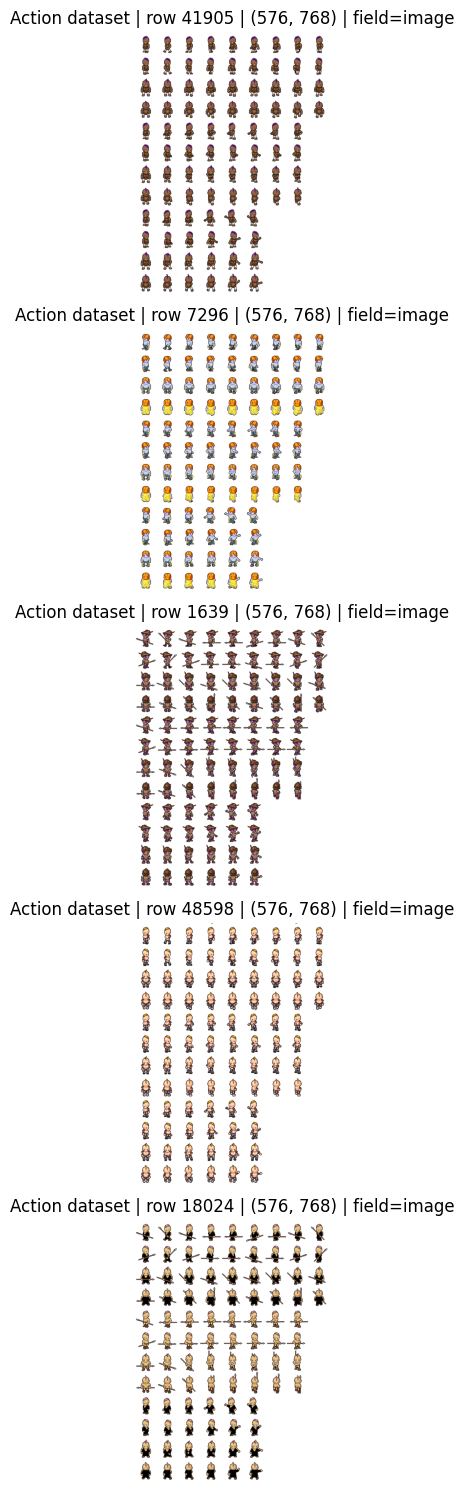

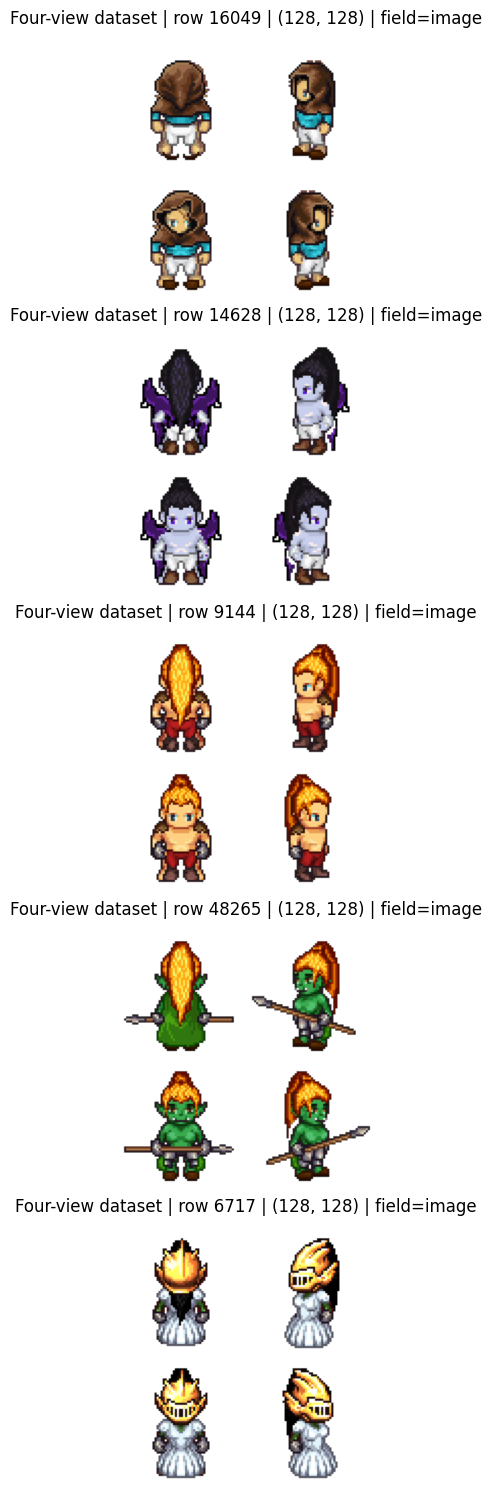

In [4]:
def get_image(row):
    # HF Image feature normally decodes to PIL; handle dict form defensively.
    for k, v in row.items():
        if isinstance(v, Image.Image):
            return v, k
        if isinstance(v, dict) and "path" in v:
            try:
                return Image.open(v["path"]).convert("RGBA"), k
            except Exception:
                pass
    return None, None

def preview_split(ds_dict, title, n=6):
    split = next(iter(ds_dict.values()))
    if not len(split):
        print("Empty dataset:", title); return
    ids = random.sample(range(len(split)), min(n, len(split)))
    fig, axes = plt.subplots(len(ids), 1, figsize=(10, 3*len(ids)))
    if len(ids) == 1: axes = [axes]
    for ax, idx in zip(axes, ids):
        im, key = get_image(split[idx])
        ax.axis("off")
        if im is not None:
            ax.imshow(im)
            ax.set_title(f"{title} | row {idx} | {im.size} | field={key}")
        else:
            ax.set_title(f"No decoded image found in row {idx}: {list(split[idx].keys())}")
    plt.tight_layout()
    plt.show()

preview_split(action_ds, "Action dataset", 5)
preview_split(fourview_ds, "Four-view dataset", 5)

## 5. Audit dimensions and image formats
The notebook must not assume all action images have the same dimensions or alpha format.

In [ ]:
def audit_images(ds_dict, name, limit=500):
    split = next(iter(ds_dict.values()))
    dims, modes, bad = {}, {}, []
    n = min(len(split), limit)
    for i in tqdm(range(n), desc=f"Audit {name}"):
        im, key = get_image(split[i])
        if im is None:
            bad.append(i); continue
        dims[im.size] = dims.get(im.size, 0) + 1
        modes[im.mode] = modes.get(im.mode, 0) + 1
    print(f"{name}: checked {n}/{len(split)} rows")
    print("Most common dimensions:", sorted(dims.items(), key=lambda x: -x[1])[:15])
    print("Modes:", modes)
    print("Rows without decoded image:", bad[:20])
    return dims, modes, bad

action_audit = audit_images(action_ds, "action")
fourview_audit = audit_images(fourview_ds, "four-view")

Audit action:   0%|          | 0/500 [00:00<?, ?it/s]

## 6. Export a small image sample locally
This is for visual inspection and later preparation. It does not create fake action labels or claim the two datasets are paired.

In [ ]:
def save_sample(ds_dict, out_dir, prefix, limit=200):
    split = next(iter(ds_dict.values()))
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    saved = 0
    for i in tqdm(range(min(len(split), limit)), desc=f"Save {prefix} sample"):
        im, _ = get_image(split[i])
        if im is None: continue
        im = im.convert("RGBA")
        im.save(out_dir / f"{prefix}_{i:06d}.png")
        saved += 1
    print("Saved", saved, "images to", out_dir)

save_sample(action_ds, DATA_DIR / "action_samples", "action", 200)
save_sample(fourview_ds, DATA_DIR / "fourview_samples", "fourview", 200)

## 7. Optional spritesheet slicing — only after confirming the grid
If the action dataset contains complete sheets, set `SHEET_GRID = (columns, rows)` in the configuration cell and rerun that cell plus this one. If sheets are not uniform grids, do not use this slicer; build a dataset-specific parser instead.

In [ ]:
if SHEET_GRID is None:
    print("SKIPPED: SHEET_GRID is None. Inspect the previews and set a verified (columns, rows) first.")
else:
    cols, rows = SHEET_GRID
    assert cols > 0 and rows > 0
    split = next(iter(action_ds.values()))
    count = 0
    for i in tqdm(range(len(split)), desc="Slice verified sheets"):
        im, _ = get_image(split[i])
        if im is None: continue
        im = im.convert("RGBA")
        w, h = im.size
        if w % cols or h % rows:
            continue
        cw, ch = w // cols, h // rows
        for r in range(rows):
            for c in range(cols):
                crop = im.crop((c*cw, r*ch, (c+1)*cw, (r+1)*ch))
                # Ignore completely transparent cells.
                if crop.getbbox() is None: continue
                crop.save(FRAME_DIR / f"sheet{i:06d}_r{r:02d}_c{c:02d}.png")
                count += 1
    print("Sliced frames:", count, "into", FRAME_DIR)
    print("NOTE: filenames preserve grid coordinates; they do not identify action names.")

## 8. Action-label / pairing readiness check
Controllable action generation needs one of these:
- explicit labels (`idle`, `walk`, `run`, `attack`, etc.) for frames/sheets, or
- a verified, documented layout that maps each grid region to an action, plus consistent character identity/reference mapping.

The notebook checks whether metadata fields beyond `image` are present. If there are no labels, this is not a controllable action dataset yet.

In [ ]:
def schema_report(name, ds_dict):
    split = next(iter(ds_dict.values()))
    print(name, "columns:", split.column_names)
    non_image_cols = [c for c in split.column_names if c != "image"]
    print("Potential metadata columns:", non_image_cols)
    if not non_image_cols:
        print("WARNING: no explicit action/character/pair labels are exposed in this split.")

schema_report("Action dataset", action_ds)
schema_report("Four-view dataset", fourview_ds)

print("\\nTraining readiness checklist:")
print("[ ] Confirm the spritesheet grid from previews")
print("[ ] Determine which rows/columns correspond to which actions")
print("[ ] Determine whether each action sheet can be matched to its character reference")
print("[ ] Verify transparent pixels and frame bounds are preserved")

## 9. Training decision
This cell intentionally blocks misleading training when action labels/pairs are absent. Unlabelled images can support style or image-distribution learning, but cannot by themselves teach reliable text/action control such as “generate a run cycle” versus “generate a walk cycle”.

Once you have a verified manifest with columns such as `character_id`, `action`, `frame_path` (and optionally `frame_index`), we can train a conditional model and split by character for validation. Do not generate labels by guessing.

In [ ]:
# A real manifest should be prepared/verified before enabling conditional training.
MANIFEST_PATH = DATA_DIR / "verified_action_manifest.csv"

if not MANIFEST_PATH.exists():
    print("TRAINING BLOCKED: no verified action manifest exists yet.")
    print("This is intentional. The two HF datasets currently appear to expose image-only rows.")
    print("Next: verify sheet layout and action labels, then create:", MANIFEST_PATH)
else:
    import pandas as pd
    manifest = pd.read_csv(MANIFEST_PATH)
    required = {"character_id", "action", "frame_path"}
    missing = required - set(manifest.columns)
    if missing:
        raise ValueError(f"Manifest missing required columns: {sorted(missing)}")
    print("Manifest rows:", len(manifest))
    print("Actions:", sorted(manifest["action"].dropna().astype(str).unique()))
    print("Characters:", manifest["character_id"].nunique())
    print(manifest.head())

## 10. Export dataset audit report
Save the inspected schemas and configuration so the next training stage can be reproducible.

In [ ]:
report = {
    "action_dataset_id": ACTION_DATASET_ID,
    "fourview_dataset_id": FOUR_VIEW_DATASET_ID,
    "action_splits": {k: {"rows": len(v), "columns": v.column_names} for k, v in action_ds.items()},
    "fourview_splits": {k: {"rows": len(v), "columns": v.column_names} for k, v in fourview_ds.items()},
    "sheet_grid": SHEET_GRID,
    "training_status": "blocked_until_verified_action_labels_and_pairs_exist",
    "note": "Image-only rows do not prove paired identity or action labels."
}
report_path = OUTPUT_DIR / "dataset_audit_report.json"
report_path.write_text(json.dumps(report, indent=2))
print("Saved:", report_path)
print(json.dumps(report, indent=2))

## What this notebook currently accomplishes
- Loads and audits both Hugging Face datasets.
- Previews images and checks dimensions/formats.
- Optionally slices action sheets using a **user-verified** grid.
- Preserves grid coordinates rather than inventing action labels.
- Blocks controllable action training until verified labels/pairs exist.
- Saves a reproducible audit report.

## What is still needed for the final walk/run/all-actions generator
1. Verify the sheet layout and which cells represent each action.
2. Build reliable character/reference-to-action associations.
3. Train a conditional frame model (and validate on held-out characters).
4. Add inference that generates action frames and assembles transparent PNG sprite sheets.

This avoids wasting GPU time on a model that reports low loss but has not learned real walk/run actions.